In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,SGDRegressor
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [2]:
x= 6 * np.random.rand(200,1) - 3
y= 0.8 * x**2 + 0.9*x  + 2 + np.random.rand(200,1)

In [ ]:
print(x.shape)
print(y.shape
      )

(200, 1)
(200, 1)


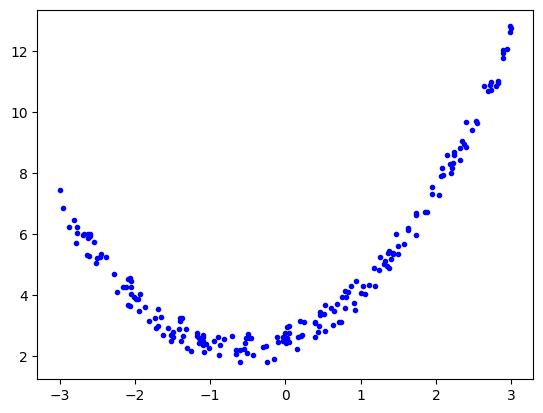

In [5]:
plt.plot(x,y,"b.")
plt.show()

In [6]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [7]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(160, 1)
(40, 1)
(160, 1)
(40, 1)


Applying Linear Regression

In [8]:
lr=LinearRegression()

In [9]:
lr.fit(x_train,y_train)

LinearRegression()

In [10]:
lr.coef_

array([[1.02740667]])

In [11]:
lr.intercept_

array([4.77203777])

In [13]:
y_pred=lr.predict(x_test)

In [14]:
r2_score(y_test,y_pred)

0.18559079319609106

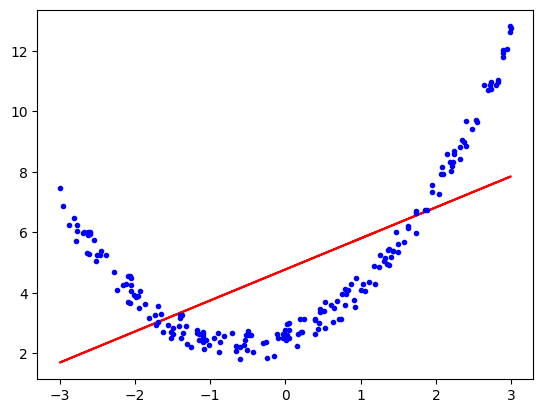

In [16]:
plt.plot(x_train,lr.predict(x_train),color="red")
plt.plot(x,y,"b.")

Applying Polynomial Regression Degree=2

In [54]:
poly=PolynomialFeatures(degree=2,include_bias=True)

In [65]:
sort_idx=np.argsort(x.flatten())
x=x[sort_idx]
y=y[sort_idx]

In [66]:
x_train_trans=poly.fit_transform(x_train)
x_test_trans=poly.transform(x_test)

In [67]:
x_train_trans.shape


(160, 3)

In [68]:
x_test_trans.shape

(40, 3)

In [69]:
print(x_train[0])
print(x_test_trans[0])

[0.90922839]
[ 1.         -2.64058671  6.97269819]


In [70]:
lr=LinearRegression()

In [71]:
lr.fit(x_train_trans,y_train)

LinearRegression()

In [72]:
y_predd=lr.predict(x_test_trans)

In [73]:
r2_score(y_test,y_predd)

0.9882339511964664

In [74]:
print(lr.coef_)
print(lr.intercept_)

[[0.         0.89511696 0.79514041]]
[2.53130813]


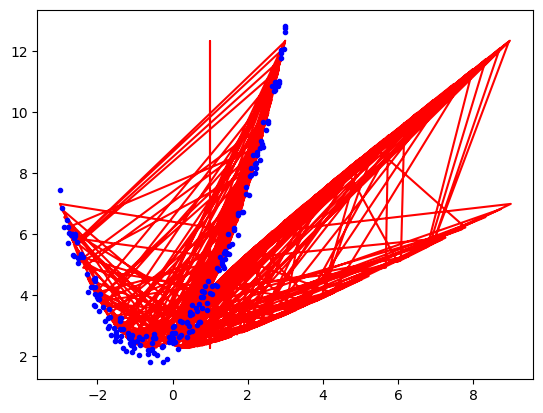

In [75]:
plt.plot(x_train_trans,lr.predict(x_train_trans),color="red")
plt.plot(x,y,"b.")
plt.show()

In [76]:
x_new=np.linspace(-3,3,200).reshape(200,1)
x_new_poly=poly.transform(x_new)
y_new=lr.predict(x_new_poly)

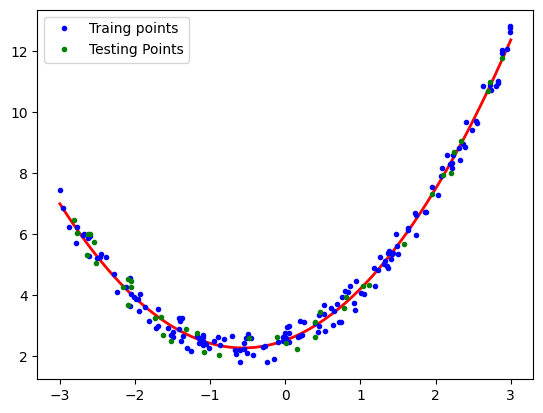

In [78]:
plt.plot(x_new,y_new,"r-",linewidth=2)
plt.plot(x_train,y_train,"b.",label="Traing points")
plt.plot(x_test,y_test,"g.",label="Testing Points")
plt.legend()
plt.show()

In [79]:
x = 7 * np.random.rand(100, 1) - 2.8
y = 7 * np.random.rand(100, 1) - 2.8

z = x**2 + y**2 + 0.2*x + 0.2*y + 0.1*x*y +2 + np.random.randn(100, 1)
# z = x^2 + y^2 + 0.2x + 0.2y + 0.1xy + 2


In [83]:
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook_connected"
df = px.data.iris()
fig = px.scatter_3d(df, x=x.ravel(), y=y.ravel(), z=z.ravel())
fig.show()